In [1]:
# https://yt.lemnoslife.com/noKey/videos?part=snippet&id=jQ1l5zenaKY

In [2]:
# 동영상 ID
video_id = "Cbij3MKhdOY"

In [26]:
event_lst = [13, 15, 21, 45, 52, 62, 68, 73, 97]

get url!!!
get url finished!!!!!


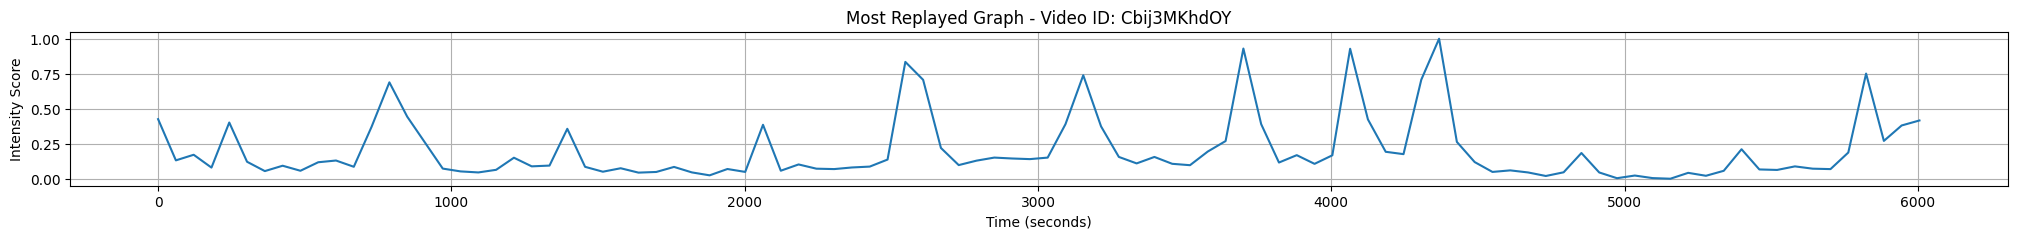

In [4]:
import requests
import json
import matplotlib.pyplot as plt


# API 엔드포인트 URL
url = f"https://yt.lemnoslife.com/videos?part=mostReplayed&id={video_id}"

# API 호출하여 JSON 데이터 가져오기
print('get url!!!')
response = requests.get(url)
print('get url finished!!!!!')
data = response.json()

# markers 리스트에서 startMillis와 intensityScoreNormalized 값 추출
markers = data['items'][0]['mostReplayed']['markers']
start_millis = [marker['startMillis'] for marker in markers]
intensity_scores = [marker['intensityScoreNormalized'] for marker in markers]

# 밀리초를 초로 변환
start_seconds = [millis / 1000 for millis in start_millis]

# 그래프 그리기
plt.figure(figsize=(25, 2))
plt.plot(start_seconds, intensity_scores)
plt.title(f'Most Replayed Graph - Video ID: {video_id}')
plt.xlabel('Time (seconds)')
plt.ylabel('Intensity Score')
plt.grid(True)
plt.show()


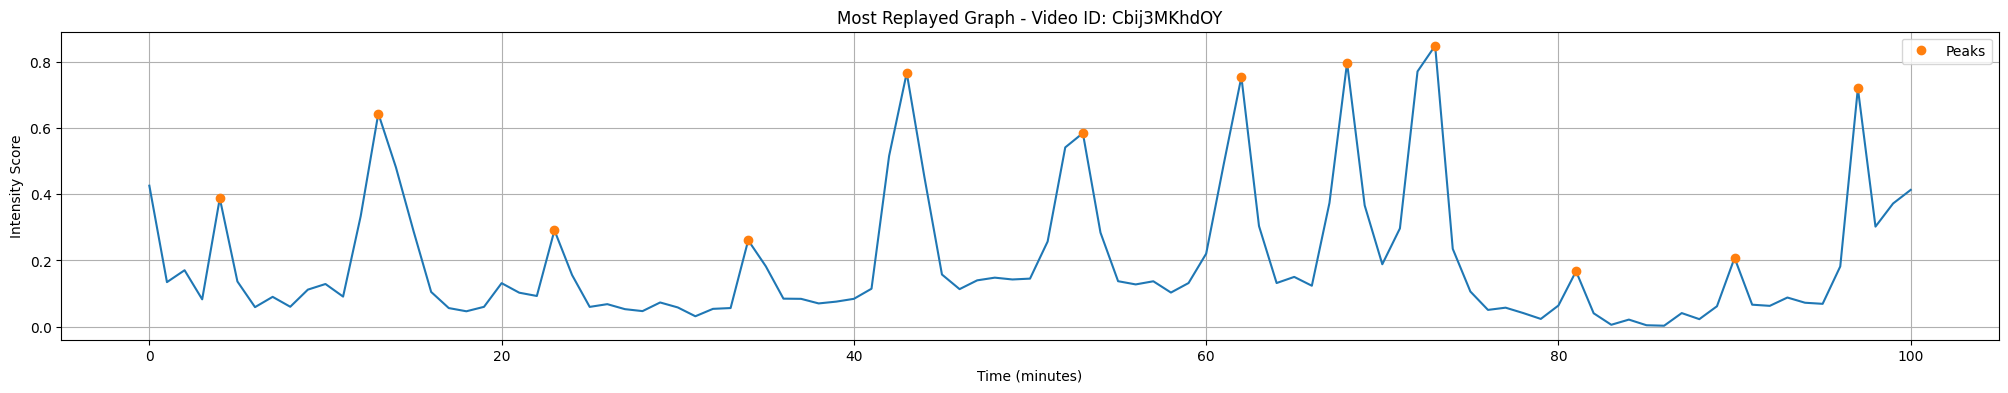

In [21]:
# 보간 함수 생성
from scipy.interpolate import interp1d
import numpy as np
from scipy.signal import find_peaks

import matplotlib.pyplot as plt

# 보간 함수 생성
interpolation_function = interp1d(start_seconds, intensity_scores, kind='linear', fill_value="extrapolate")

# 1분 간격으로 새로운 시간 생성
total_duration_seconds = start_seconds[-1]
total_duration_minutes = total_duration_seconds / 60
new_time_minutes = np.arange(0, total_duration_minutes, 1) * 60  # 초 단위로 변환

# 새로운 시간에 대한 보간된 값 계산
smoothed_intensity_scores = interpolation_function(new_time_minutes)
peaks, _ = find_peaks(smoothed_intensity_scores, prominence=0.1)

# 그래프 그리기
plt.figure(figsize=(25, 4))
plt.plot(new_time_minutes / 60, smoothed_intensity_scores)  # 분으로 변환하여 표시
plt.plot(new_time_minutes[peaks] / 60, smoothed_intensity_scores[peaks], "o", label='Peaks')

plt.title(f'Most Replayed Graph - Video ID: {video_id}')
plt.xlabel('Time (minutes)')
plt.ylabel('Intensity Score')
plt.grid(True)
plt.legend()
plt.show()


In [23]:
len(smoothed_intensity_scores)

101

In [27]:
peaks

array([ 4, 13, 23, 34, 43, 53, 62, 68, 73, 81, 90, 97], dtype=int64)

In [28]:
rewards_lst = smoothed_intensity_scores

In [29]:
class State:
    def __init__(self, peak_int, count, time, rewards_lst= rewards_lst, ):
        self.peak = peak_int
        self.frame = -1
        self.count = count
        self.time = time
        self.reward = rewards_lst[time]
        self.next_states = []
        self.choose = False

    def get_info(self):
        info = f'Peak: {self.peak}, Count: {self.count}, choose: {self.choose}, Time: {self.time}, Next State {self.next_states}'
        # info = f'Peak: {self.peak}, Count: {self.count},  Next State {self.next_states}'
        return info




In [32]:
# count_durations = []  # 각 피크마다 count_duration을 계산해서 저장

# 각 피크마다 count_duration 계산
# for i, peak in enumerate(peaks):
#     if i < len(peaks) - 1:
#         count_duration = min(50, peaks[i + 1] - peak)
#     else:
#         count_duration = min(50, len(smoothed_intensity_scores) - peak)
#     count_durations.append(count_duration)

In [33]:
states = []
# count_duration = 20 ### 제한 시간
total_length = len(smoothed_intensity_scores)
for i, peak in enumerate(peaks, start=1):
    for j in range(total_length - peak):
        temp = peak + j
        reward = smoothed_intensity_scores[temp]
        time = temp
        state = State(peak_int=i, count=j, time = time )
        states.append(state)

In [34]:
for state in states:
    if state.count == 0:
        state.choose = True

In [35]:
for state in states:
    print(state.get_info())


Peak: 1, Count: 0, choose: True, Time: 4, Next State []
Peak: 1, Count: 1, choose: False, Time: 5, Next State []
Peak: 1, Count: 2, choose: False, Time: 6, Next State []
Peak: 1, Count: 3, choose: False, Time: 7, Next State []
Peak: 1, Count: 4, choose: False, Time: 8, Next State []
Peak: 1, Count: 5, choose: False, Time: 9, Next State []
Peak: 1, Count: 6, choose: False, Time: 10, Next State []
Peak: 1, Count: 7, choose: False, Time: 11, Next State []
Peak: 1, Count: 8, choose: False, Time: 12, Next State []
Peak: 1, Count: 9, choose: False, Time: 13, Next State []
Peak: 1, Count: 10, choose: False, Time: 14, Next State []
Peak: 1, Count: 11, choose: False, Time: 15, Next State []
Peak: 1, Count: 12, choose: False, Time: 16, Next State []
Peak: 1, Count: 13, choose: False, Time: 17, Next State []
Peak: 1, Count: 14, choose: False, Time: 18, Next State []
Peak: 1, Count: 15, choose: False, Time: 19, Next State []
Peak: 1, Count: 16, choose: False, Time: 20, Next State []
Peak: 1, Count

In [36]:
# 다음 상태 정의 함수
import pdb
def fill_next_states(states, min_duration):
    for state in states:
        next_states = []
        
        for next_state in states:
            
            # 같은 피크 내에서 다음 상태로 전이, 같은 피크 내에서는 1개씩만. 
            if (next_state.peak == state.peak) and (next_state.count == state.count + 1):
                next_states.append(next_state)
                state.choose = True

            # 다음 피크를 선택할 때에는 
            # 진행중인 state가 2초 이상이고,          다음 피트가 현재 피크랑 다르고        피크이고                    현재 지속 시간보다 
            elif  (state.count >= min_duration) and (next_state.peak > state.peak) and (next_state.count == 0) and (state.time < next_state.time):
                next_states.append(next_state)
                state.choose = True
        # print("=======")
        
        if state.choose:
            state.next_states = next_states
        # print(state.next_states)

fill_next_states(states, min_duration=2)


In [37]:
for state in states:
    # print(f"===={state.get_info()}")
    # print(state.next_states)
    for next in state.next_states:
        print(next.get_info())

Peak: 1, Count: 1, choose: True, Time: 5, Next State [<__main__.State object at 0x000002A85A1A8310>]
Peak: 1, Count: 2, choose: True, Time: 6, Next State [<__main__.State object at 0x000002A85A1AA020>, <__main__.State object at 0x000002A859FBD750>, <__main__.State object at 0x000002A85A004EB0>, <__main__.State object at 0x000002A85A006470>, <__main__.State object at 0x000002A85A067190>, <__main__.State object at 0x000002A85A067C70>, <__main__.State object at 0x000002A85A08C280>, <__main__.State object at 0x000002A85A08C9D0>, <__main__.State object at 0x000002A85A08D000>, <__main__.State object at 0x000002A85A08D540>, <__main__.State object at 0x000002A85A08D900>, <__main__.State object at 0x000002A85A08DB10>]
Peak: 1, Count: 3, choose: True, Time: 7, Next State [<__main__.State object at 0x000002A85A1A86A0>, <__main__.State object at 0x000002A859FBD750>, <__main__.State object at 0x000002A85A004EB0>, <__main__.State object at 0x000002A85A006470>, <__main__.State object at 0x000002A85A0

In [38]:
def find_highlights(states, temp_states, F):
    dp = np.zeros((len(states), F+1))
    path = [[None for _ in range(F+1)] for _ in range(len(states))]

    for f in range(1, F+1):
        for i, state in enumerate(states):
            for j, temp_state in enumerate(temp_states):
                max_prev_reward = -float('inf')
                best_prev_state = None

    for f in range(1, F+1):
        for i, state in enumerate(states):
            if state.count == 0:
                # print(" here ")
                # print(state.get_info())
                dp[i][f] = state.reward
                path[i][f] = i
            else:
                max_prev_reward = -float('inf')
                best_prev_state = None
                for prev_state in state.next_states:
                    prev_idx = states.index(prev_state)
                    # df [i+1][f]
                    if dp[prev_idx][f-1] + state.reward > max_prev_reward:
                        max_prev_reward = dp[prev_idx][f-1] + state.reward
                        best_prev_state = prev_idx
                if best_prev_state is not None:
                    dp[i][f] = max_prev_reward
                    path[i][f] = best_prev_state

    highlights = []
    highlights_peaks = []
    state_idx = np.argmax(dp[:, -1])
    f = F
    while f > 0 and state_idx is not None:
        highlights.append(states[state_idx].time)
        state_idx = path[state_idx][f]
        print(states[state_idx].peak, states[state_idx].count)
        if states[state_idx].count == 0:
            print("hello")
            highlights_peaks.append(states[state_idx].time)
        f -= 1

    return highlights, highlights_peaks





In [39]:
total_length = 10

In [40]:
highlights, highlights_peaks = find_highlights(states, total_length)


TypeError: find_highlights() missing 1 required positional argument: 'F'

In [ ]:
highlights_peaks

[47, 47, 47, 47, 47, 47, 47, 47, 47, 47]

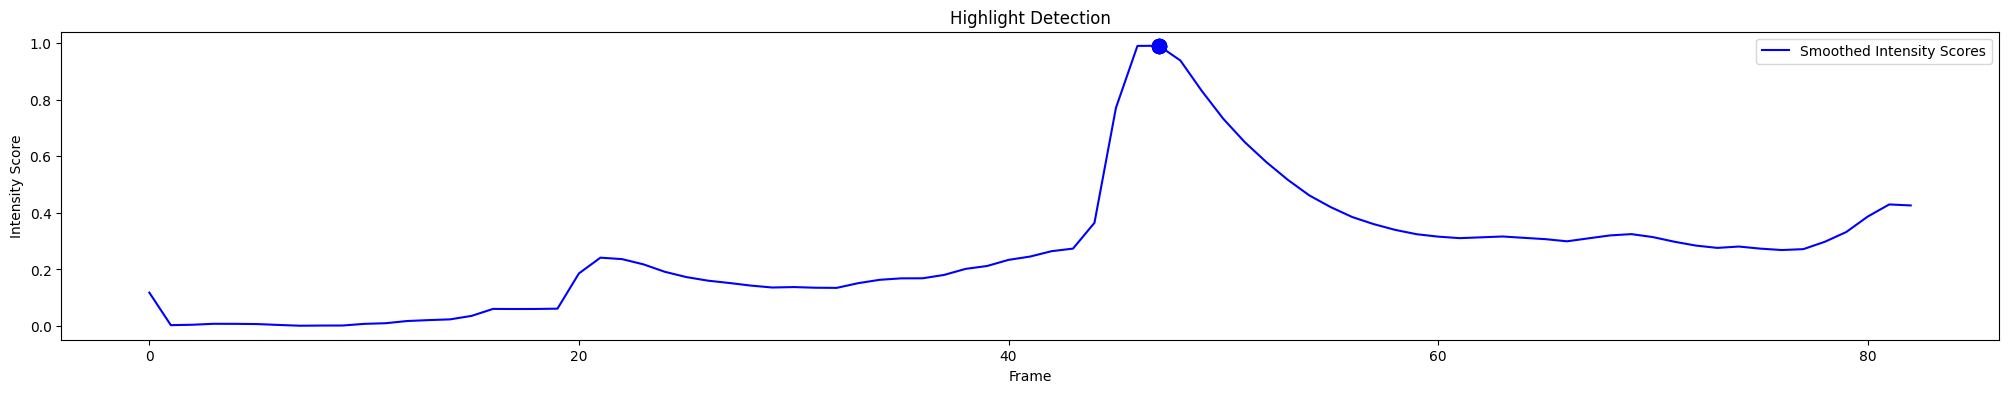

In [ ]:
# 그래프 그리기
plt.figure(figsize=(25, 4))
plt.plot(smoothed_intensity_scores, 'b-', label='Smoothed Intensity Scores')
# 점을 그래프에 표시
for point in highlights:
    plt.scatter(point, smoothed_intensity_scores[point], color='red', s=50)  # s는 점의 크기

for point in highlights_peaks:
    plt.scatter(point, smoothed_intensity_scores[point], color='blue', s=100)  # s는 점의 크기

plt.xlabel('Frame')
plt.ylabel('Intensity Score')
plt.title('Highlight Detection')
plt.legend()
plt.show()

# 앞뒤로 해보기